In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Layer, Dense
from tensorflow.nn import relu
from tensorflow.keras.losses import BinaryCrossentropy
from sionna.phy.block import Block
from sionna.phy.utils import expand_to_rank, hard_decisions
import importlib
import pn_classes
importlib.reload(pn_classes)
from pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder
import sionna as sn
import matplotlib.pyplot as plt
import os
import gc
from sionna.phy.mapping import Constellation, Demapper, SymbolLogits2LLRs, BinarySource
from sionna.phy.utils import split_dim

2026-11-25 12:17:04.833580: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795601824.883718    7320 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795601824.896791    7320 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1795601824.996620    7320 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795601824.996639    7320 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1795601824.996640    7320 computation_placer.cc:177] computation placer alr

In [2]:
symbol_points_qam64 = np.array([-1.08012344973464 + 1.08012344973464j
,-1.08012344973464 + 0.771516749810460j
,-1.08012344973464 + 0.154303349962092j
,-1.08012344973464 + 0.462910049886276j
,-0.771516749810460 + 1.08012344973464j
,-0.771516749810460 + 0.771516749810460j
,-0.771516749810460 + 0.154303349962092j
,-0.771516749810460 + 0.462910049886276j
,-0.154303349962092 + 1.08012344973464j
,-0.154303349962092 + 0.771516749810460j
,-0.154303349962092 + 0.154303349962092j
,-0.154303349962092 + 0.462910049886276j
,-0.462910049886276 + 1.08012344973464j
,-0.462910049886276 + 0.771516749810460j
,-0.462910049886276 + 0.154303349962092j
,-0.462910049886276 + 0.462910049886276j
,-1.08012344973464 - 1.08012344973464j
,-1.08012344973464 - 0.771516749810460j
,-1.08012344973464 - 0.154303349962092j
,-1.08012344973464 - 0.462910049886276j
,-0.771516749810460 - 1.08012344973464j
,-0.771516749810460 - 0.771516749810460j
,-0.771516749810460 - 0.154303349962092j
,-0.771516749810460 - 0.462910049886276j
,-0.154303349962092 - 1.08012344973464j
,-0.154303349962092 - 0.771516749810460j
,-0.154303349962092 - 0.154303349962092j
,-0.154303349962092 - 0.462910049886276j
,-0.462910049886276 - 1.08012344973464j
,-0.462910049886276 - 0.771516749810460j
,-0.462910049886276 - 0.154303349962092j
,-0.462910049886276 - 0.462910049886276j
,1.08012344973464 + 1.08012344973464j
,1.08012344973464 + 0.771516749810460j
,1.08012344973464 + 0.154303349962092j
,1.08012344973464 + 0.462910049886276j
,0.771516749810460 + 1.08012344973464j
,0.771516749810460 + 0.771516749810460j
,0.771516749810460 + 0.154303349962092j
,0.771516749810460 + 0.462910049886276j
,0.154303349962092 + 1.08012344973464j
,0.154303349962092 + 0.771516749810460j
,0.154303349962092 + 0.154303349962092j
,0.154303349962092 + 0.462910049886276j
,0.462910049886276 + 1.08012344973464j
,0.462910049886276 + 0.771516749810460j
,0.462910049886276 + 0.154303349962092j
,0.462910049886276 + 0.462910049886276j
,1.08012344973464 - 1.08012344973464j
,1.08012344973464 - 0.771516749810460j
,1.08012344973464 - 0.154303349962092j
,1.08012344973464 - 0.462910049886276j
,0.771516749810460 - 1.08012344973464j
,0.771516749810460 - 0.771516749810460j
,0.771516749810460 - 0.154303349962092j
,0.771516749810460 - 0.462910049886276j
,0.154303349962092 - 1.08012344973464j
,0.154303349962092 - 0.771516749810460j
,0.154303349962092 - 0.154303349962092j
,0.154303349962092 - 0.462910049886276j
,0.462910049886276 - 1.08012344973464j
,0.462910049886276 - 0.771516749810460j
,0.462910049886276 - 0.154303349962092j
,0.462910049886276 - 0.462910049886276j])


symbol_points_apsk64 = np.array([0.115390173049244 - 0.580105573973698j
,0.988550281390018 - 0.988550281390019j
,0.328603411315507 - 0.491789759006325j
,0.684380964039243 - 0.684380964039244j
,0.218698700888034 - 1.38080925398929j
,0.634688350057733 - 1.24564602354504j
,0.151406792922485 - 0.955944868146431j
,0.439399626963046 - 0.862370323992718j
,0.102884530208982 - 0.248385228188907j
,1.24564602354504 - 0.634688350057733j
,0.491789759006325 - 0.328603411315507j
,0.862370323992718 - 0.439399626963046j
,0.248385228188907 - 0.102884530208982j
,1.38080925398929 - 0.218698700888034j
,0.580105573973698 - 0.115390173049244j
,0.955944868146430 - 0.151406792922485j
,-0.115390173049244 - 0.580105573973698j
,-0.988550281390019 - 0.988550281390018j
,-0.328603411315507 - 0.491789759006325j
,-0.684380964039244 - 0.684380964039243j
,-0.218698700888034 - 1.38080925398929j
,-0.634688350057733 - 1.24564602354504j
,-0.151406792922485 - 0.955944868146430j
,-0.439399626963046 - 0.862370323992718j
,-0.102884530208982 - 0.248385228188907j
,-1.24564602354504 - 0.634688350057732j
,-0.491789759006326 - 0.328603411315507j
,-0.862370323992718 - 0.439399626963045j
,-0.248385228188907 - 0.102884530208981j
,-1.38080925398929 - 0.218698700888034j
,-0.580105573973698 - 0.115390173049244j
,-0.955944868146431 - 0.151406792922485j
,0.115390173049244 + 0.580105573973698j
,0.988550281390019 + 0.988550281390018j
,0.328603411315507 + 0.491789759006325j
,0.684380964039244 + 0.684380964039243j
,0.218698700888034 + 1.38080925398929j
,0.634688350057733 + 1.24564602354504j
,0.151406792922485 + 0.955944868146431j
,0.439399626963046 + 0.862370323992718j
,0.102884530208981 + 0.248385228188907j
,1.24564602354504 + 0.634688350057733j
,0.491789759006325 + 0.328603411315507j
,0.862370323992718 + 0.439399626963046j
,0.248385228188907 + 0.102884530208981j
,1.38080925398929 + 0.218698700888034j
,0.580105573973698 + 0.115390173049244j
,0.955944868146431 + 0.151406792922485j
,-0.115390173049244 + 0.580105573973698j
,-0.988550281390018 + 0.988550281390019j
,-0.328603411315507 + 0.491789759006325j
,-0.684380964039243 + 0.684380964039244j
,-0.218698700888034 + 1.38080925398929j
,-0.634688350057733 + 1.24564602354504j
,-0.151406792922485 + 0.955944868146431j
,-0.439399626963046 + 0.862370323992718j
,-0.102884530208981 + 0.248385228188907j
,-1.24564602354504 + 0.634688350057733j
,-0.491789759006325 + 0.328603411315507j
,-0.862370323992718 + 0.439399626963046j
,-0.248385228188907 + 0.102884530208982j
,-1.38080925398929 + 0.218698700888034j
,-0.580105573973698 + 0.115390173049244j
,-0.955944868146430 + 0.151406792922485j])


In [3]:

class Demapper_trainable(Demapper):
    def __init__(self,
                 demapping_method,
                 constellation_type=None,
                 num_bits_per_symbol=None,
                 constellation=None,
                 hard_out=False,
                 precision=None,
                 **kwargs):
        super().__init__(demapping_method=demapping_method, constellation=constellation, precision=precision, **kwargs)

        # Create constellation object
        self._constellation = Constellation.check_or_create(
            constellation_type=constellation_type,
            num_bits_per_symbol=num_bits_per_symbol,
            constellation=constellation,
            precision=precision)

        num_bits_per_symbol = self._constellation.num_bits_per_symbol

        self._logits2llrs = SymbolLogits2LLRs(demapping_method,
                                              num_bits_per_symbol,
                                              hard_out=hard_out,
                                              precision=precision,
                                              **kwargs)

        self._no_threshold = tf.cast(np.finfo(self.rdtype.as_numpy_dtype).tiny,
                                     self.rdtype)

    def call(self, y, no, points, prior=None):
        # Compute squared distances from y to all points
        # shape [...,n,num_points]
        squared_dist = tf.pow(tf.abs(tf.expand_dims(y, axis=-1) - points), 2)

        # Add a dummy dimension for broadcasting. This is not needed when no
        # is a scalar, but also does not do any harm.
        no = tf.expand_dims(no, axis=-1)
        # Deal with zero or very small values.
        no = tf.math.maximum(no, self._no_threshold)

        # Compute exponents
        exponents = -squared_dist / no
        llr = self._logits2llrs(exponents, prior)

        # Reshape LLRs to [...,n*num_bits_per_symbol]
        out_shape = tf.concat([tf.shape(y)[:-1],
                               [y.shape[-1] * \
                                self.constellation.num_bits_per_symbol]], 0)

        llr_reshaped = tf.reshape(llr, out_shape)

        return llr_reshaped


def normalize_constellation(points, probabilities):
    # Compute the power of the constellation
    power = np.sum(probabilities * np.abs(points) ** 2)
    # Normalize the constellation points
    normalized_points = points / np.sqrt(power)
    return normalized_points


def plot_constellation_wlabels(points, probabilities, plot_title):
    points = np.asarray(points)
    probabilities = np.asarray(probabilities).flatten()

    # Scale marker sizes for visibility
    marker_sizes = 300 * probabilities / max(probabilities)

    plt.figure(figsize=(8, 8))
    plt.scatter(points.real, points.imag, s=marker_sizes, alpha=0.7, c='b', edgecolors='k')

    # Annotate with 6-bit binary labels
    for i, pt in enumerate(points):
        label = format(i, '06b')  # 6-bit binary string
        plt.text(pt.real + 0.05, pt.imag + 0.05, label, fontsize=9, ha='left', va='bottom', color='darkred')

    # Add grid and formatting
    plt.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.grid(True, linestyle=':')
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(plot_title)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.tight_layout()
    # plt.show()


class Mapper_trainable(Layer):
    def __init__(self, num_bits_per_symbol, constellation, **kwargs):
        super(Mapper_trainable, self).__init__(**kwargs)
        self.num_bits_per_symbol = num_bits_per_symbol
        self._bit_positions = tf.cast(tf.range(num_bits_per_symbol-1, -1, -1), dtype=tf.int32)

        self.constellation_real_init = constellation.real
        self.constellation_imag_init = constellation.imag

    def build(self, input_shape):
        self.constellation_real = self.add_weight(
            name="constellation_real",
            shape=self.constellation_real_init.shape,
            initializer=tf.constant_initializer(self.constellation_real_init),
            trainable=True
        )
        self.constellation_imag = self.add_weight(
            name="constellation_imag",
            shape=self.constellation_imag_init.shape,
            initializer=tf.constant_initializer(self.constellation_imag_init),
            trainable=True
        )


    def call(self, bits):

        C_points = tf.complex(self.constellation_real, self.constellation_imag)
        norm_C_points = C_points / tf.complex(tf.sqrt(tf.reduce_mean(tf.square(tf.abs(C_points)))),0.0)

         # Convert to int32
        bits = tf.cast(bits, dtype=tf.int32)

        # Reshape last dimensions to the desired format
        n1 = int(bits.shape[-1]/self.num_bits_per_symbol)
        new_shape = [n1 , self.num_bits_per_symbol]
        bits = split_dim(bits, new_shape, axis=tf.rank(bits)-1)

        # Use bitwise left shift to compute powers of two
        shifted_bits = tf.bitwise.left_shift(bits, self._bit_positions)

        # Compute the integer representation using bitwise operations
        int_rep = tf.reduce_sum(shifted_bits, axis=-1)

        # Map integers to constellation symbols
        x = tf.gather(norm_C_points, int_rep)
        return x, norm_C_points

In [4]:
class E2E_GCS_PAPR_PN(Model):
    def __init__(self, N, constellation, device, constellation_orig, use_upsampling_filtering, batch_size, papr_batch_size, block_size):
        super().__init__()
        print('device', device)

        # self.sampling = SamplingMechanism_P0_trainable_parameter(N, tau, device, constellation)
        # self.sampling = Sampling_sym_sub_constellation(N, parity_k, tau, device, constellation, use_uniform)
        # self.modulator = Modulator()
        self.channel = sn.phy.channel.AWGN()
        self.demodulator_test = Demapper_trainable("app", constellation=constellation_orig)
        self.loss_fn = BinaryCrossentropy(from_logits=True, reduction=None, axis=0)
        self.N = N
        self.bits_per_symbol = int(np.log2(self.N))
        # self.bit_labels = tf.convert_to_tensor(np.array([[int(b) for b in format(i, f'0{self.bits_per_symbol}b')] for i in range(self.N)]),tf.float32)

        self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
        self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                         samples_per_symbol=4,
                                                         span_in_symbols=32)
        self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                      offset = self.rx_filter.length - 1,
                                                 num_symbols=tf.cast(block_size+128, tf.int32))
        self.use_upsampling_filtering = use_upsampling_filtering

        self.mapper = Mapper_trainable(self.bits_per_symbol, constellation)
        self.binary_source = BinarySource()
        self.batch_size = batch_size
        self.papr_batch_size = papr_batch_size
        self.block_size = block_size

        num_ptrs_blocks = 32
        symbols_per_ptrs_block = 4
        block_size_ptrs = block_size+128
        bandwidth = 960e3*4096
        fc = 220e9
        samples = 4*(block_size_ptrs+32)

        path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_32.mat"
        self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
        self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs, self.ptrs_adder.pilots, batch_size)
        self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
        self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)

        self.prior_values = tf.convert_to_tensor(np.zeros(self.bits_per_symbol), tf.float32)

    def call(self, ebno_db, No):

        bit_input = self.binary_source([self.batch_size, self.block_size * self.bits_per_symbol])
        x_mod, norm_C_points = self.mapper(bit_input)
        ptrs_x_mod = self.ptrs_adder(x_mod)

        if self.use_upsampling_filtering:
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, No)
            y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel_pn)
            y = self.downsampler(y_rx_filt)
            _, y_data_vec = self.pn_compensate(y)

        else:
            # Transmit through the channel
            y = self.channel(x_mod, No)

        # Demodulate the received signal
        tf_points = tf.reshape(norm_C_points, (1, 1, self.N))
        logits = self.demodulator_test(y_data_vec, No, tf_points, self.prior_values)

        logits_reshaped = tf.reshape(logits, (self.batch_size, self.block_size, self.bits_per_symbol))
        bit_input_reshaped = tf.reshape(bit_input, (self.batch_size, self.block_size, self.bits_per_symbol))

        bce_matrix = tf.nn.sigmoid_cross_entropy_with_logits(labels=bit_input_reshaped, logits=logits_reshaped)
        loss_ordinary = tf.reduce_sum(tf.math.reduce_mean(bce_matrix, axis=[0,1]))

        # y_raw_data = tf.gather(y, self.ptrs_adder.data_indices, axis=1)

        loss = loss_ordinary - self.bits_per_symbol

        return loss, loss_ordinary#, y_raw_data, y_data_vec, bit_input_reshaped, logits_reshaped, x_mod

    @tf.function
    def compute_power_to_average_power_samples(self, papr_batch_size, papr_block_size):
        bits_power = self.binary_source([papr_batch_size, papr_block_size * self.bits_per_symbol])
        x_power,_ = self.mapper(bits_power)
        x_up_power = self.upsampler(x_power)
        x_tx_filt_power = self.tx_filter(x_up_power)  # 'same' for discarding the edges
        p_x = tf.square(tf.abs(x_tx_filt_power))
        power_samples = p_x / tf.reduce_mean(p_x)
        return power_samples


In [5]:
N = 64
num_bits_symbol = np.log2(N)
constellation_orig = Constellation("pam", num_bits_per_symbol=6)
tau = 10
parity_k = 0
use_upsampling_filtering = True
uniform_input = True

device = "/GPU:0" if tf.config.list_physical_devices('GPU') else "/CPU:0"

batch_size = 10
papr_batch_size = 20
block_size = 4096

ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=16.0)
No_ = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=num_bits_symbol, coderate=1)
No_ = tf.expand_dims(No_, axis=-1)

model = E2E_GCS_PAPR_PN(N, symbol_points_apsk64, device,
        constellation_orig, use_upsampling_filtering, batch_size,
                        papr_batch_size, block_size)

_, _ = model(ebno_db,No_)
initial_weights = model.get_weights()

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

I0000 00:00:1795601892.199795    7320 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5898 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050, pci bus id: 0000:01:00.0, compute capability: 8.6


device /GPU:0


I0000 00:00:1795601893.504443    7320 cuda_dnn.cc:529] Loaded cuDNN version 91400


In [6]:
## Inner loop
@tf.function
def _inner_loop(lambd_papr, mu, step, num_it, excess_power_target, papr_threshold, No):
    # We need to initialize c...
    excess_power = 0.0
    c_excess_power = excess_power
    L = 0.0

    k = tf.constant(0, tf.int32)
    while tf.less(k, num_it):
        with tf.GradientTape() as tape:
            ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=20.0)
            No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=num_bits_symbol, coderate=1)
            No = tf.expand_dims(No, axis=-1)
            # Running the system
            loss, loss_ordinary  = model(ebno_db, No)

            if use_upsampling_filtering:
                powers = model.compute_power_to_average_power_samples(
                    papr_batch_size, block_size)
                excess_power = tf.reduce_mean(tf.nn.relu(powers  - papr_threshold))
                excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
                c_excess_power = excess_power - (excess_power_target)
                c_excess_power = tf.maximum(c_excess_power,lambd_papr / mu)

            # Augmented Lagrangian
            L = loss - lambd_papr * c_excess_power + 0.5 * mu * (tf.square(c_excess_power))

        # Computing and applying gradients
        weights = model.trainable_weights
        grads = tape.gradient(L, weights)
        grads, glob_norm = tf.clip_by_global_norm(grads, 0.1)
        optimizer.apply_gradients(zip(grads, weights))
        if k % 50 == 0:
          tf.print('Iteration',k,'L', L / np.log(2),'loss', loss / np.log(2), 'loss_ordinary', loss_ordinary / np.log(2), 'glob_norm',glob_norm)

        k = k + 1
        step = step + 1

    if use_upsampling_filtering:
        # norm_constant = tf.cast(tf.expand_dims(tf.reduce_sum(tf.squeeze(shaping_probs, axis=2)*tf.abs(norm_C_points)**2,axis=1),axis=1),tf.complex64)
        # norm_C_points = norm_C_points/tf.sqrt(norm_constant)
        powers = model.compute_power_to_average_power_samples(papr_batch_size, block_size)
        excess_power = tf.reduce_mean(tf.nn.relu(powers - papr_threshold))
        excess_power = tf.math.log(excess_power + 1e-12) / tf.math.log(10.)
        c_excess_power = excess_power - (excess_power_target)
        c_excess_power = tf.maximum(c_excess_power, lambd_papr / mu)

    return c_excess_power, step


In [7]:
ebno_db = tf.random.uniform(shape=[batch_size], minval=8.0, maxval=16.0)
No_ = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=num_bits_symbol, coderate=1)
No_ = tf.expand_dims(No_, axis=-1)

papr_threshold_db = 8.0

# No_ = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
papr_threshold_ = tf.math.pow(10.0, papr_threshold_db / 10.0)
excess_power_target_ = -6.0  # B

lambd_papr = tf.Variable(tf.constant(0.0, tf.float32), trainable=False, dtype=tf.float32)
mu = tf.Variable(0.01, trainable=False, dtype=tf.float32)
step = tf.constant(0, tf.int32)

for i in range(1):
    if i == 0:
        num_it = 100000
    else:
        num_it = 35
    c_excess_power, step = _inner_loop(lambd_papr, mu, step,
                                       num_it, excess_power_target_,
                                       papr_threshold_, No_)

    # Update Lagrange multipliers
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')
    tf.print('Progress ', i, ' % ', 'c_excess_power', c_excess_power, 'lambd_papr', lambd_papr, 'mu', mu)
    tf.print('-------------------------------------------------------')
    tf.print('-------------------------------------------------------')
    lambd_papr = lambd_papr - mu * c_excess_power

    # Update penalty parameter
    mu = mu * 1.003

Iteration 0 L -6.92112875 loss -6.92112875 loss_ordinary 1.73504162 glob_norm 0.1691989
Iteration 50 L -6.96058083 loss -6.96058083 loss_ordinary 1.69558966 glob_norm 0.600527048
Iteration 100 L -7.30465221 loss -7.30465221 loss_ordinary 1.35151768 glob_norm 0.648178339
Iteration 150 L -7.61131573 loss -7.61131573 loss_ordinary 1.04485428 glob_norm 0.348680615
Iteration 200 L -7.92722511 loss -7.92722511 loss_ordinary 0.728945374 glob_norm 0.262564927
Iteration 250 L -7.77130556 loss -7.77130556 loss_ordinary 0.88486433 glob_norm 0.216814891
Iteration 300 L -7.74118805 loss -7.74118805 loss_ordinary 0.91498208 glob_norm 0.241094157
Iteration 350 L -8.04023266 loss -8.04120731 loss_ordinary 0.614962935 glob_norm 0.180269435
Iteration 400 L -7.74082565 loss -7.74117136 loss_ordinary 0.914998949 glob_norm 0.14323999
Iteration 450 L -7.85481787 loss -7.85712957 loss_ordinary 0.799040318 glob_norm 0.24307543
Iteration 500 L -7.93643713 loss -7.93865585 loss_ordinary 0.717514515 glob_norm 0.

In [8]:
ebno_db = tf.random.uniform(shape=[1], minval=10.0, maxval=10.2)
No = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=num_bits_symbol, coderate=1)
No = tf.expand_dims(No, axis=-1)

with tf.GradientTape(persistent=False) as tape:
    _, _ = model(ebno_db, No)

C_points = tf.complex(model.mapper.constellation_real, model.mapper.constellation_imag)
norm_C_points = C_points / tf.complex(tf.sqrt(tf.reduce_mean(tf.square(tf.abs(C_points)))), 0.0)
points = norm_C_points.numpy().flatten()
probabilities = np.ones(points.shape[0]) / points.shape[0]
normalized_points = normalize_constellation(points, probabilities)

[0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625]
PAPR_8.0


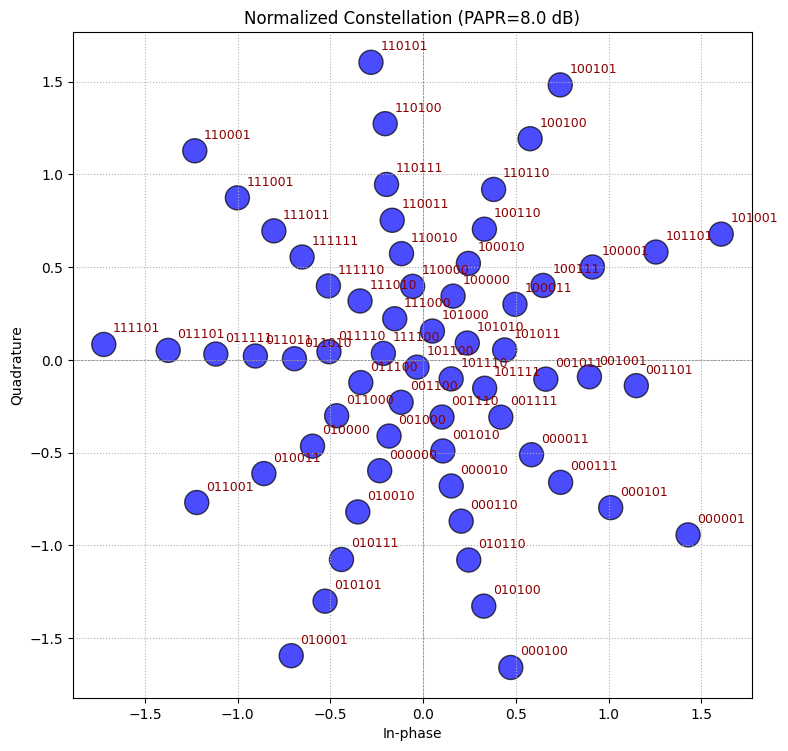

In [9]:


title_plot = f"Normalized Constellation (PAPR={papr_threshold_db} dB)"
# Plot the constellation
plot_constellation_wlabels(normalized_points, probabilities, title_plot)
file_name = f"PAPR_{papr_threshold_db}"
print(probabilities)
print(file_name)

[0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625]
PAPR_8.0


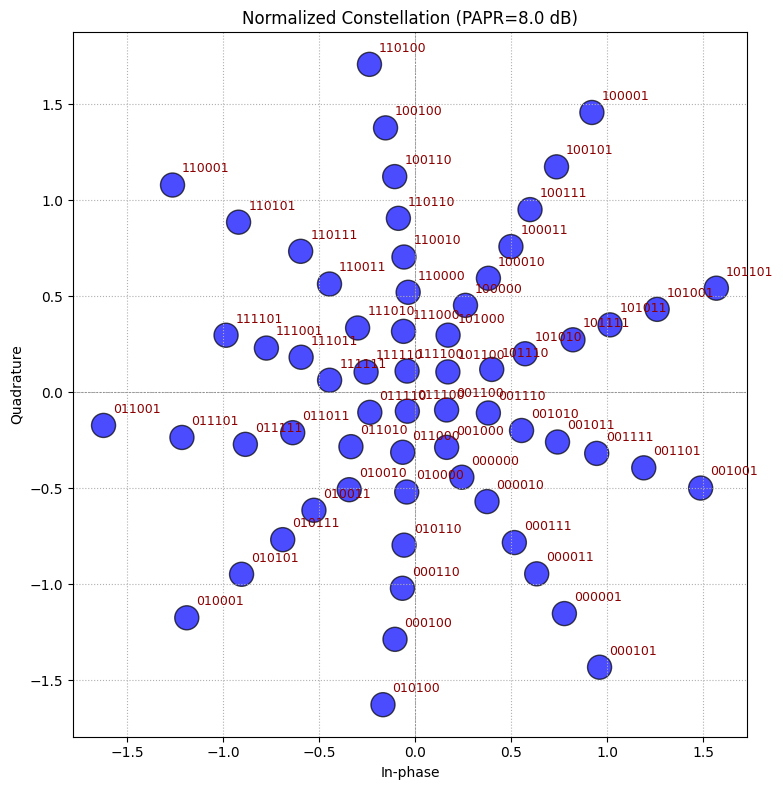

[0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625
 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625 0.015625]
PAPR_8.0


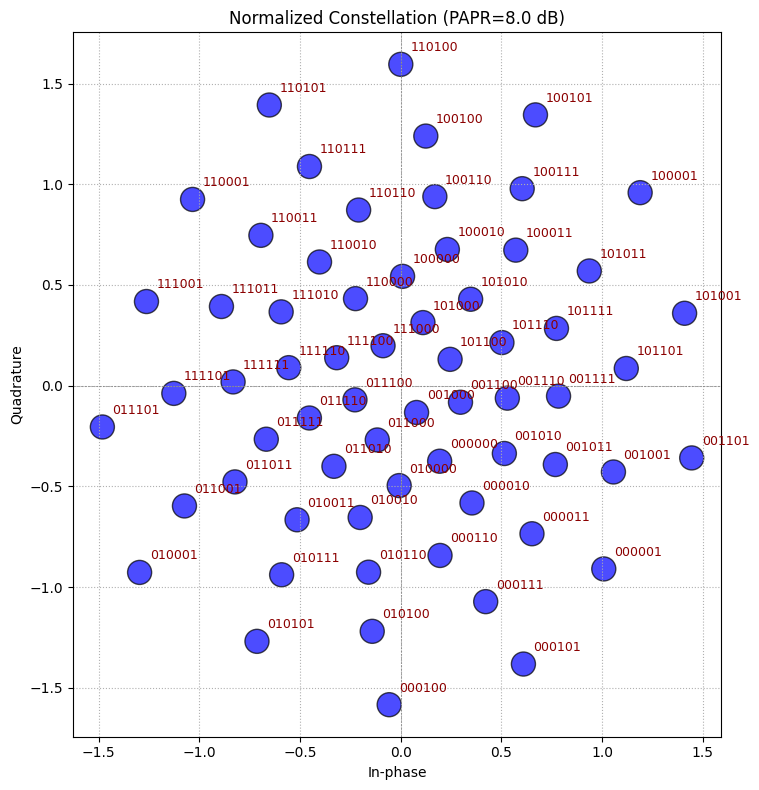

In [10]:
powers = tf.reshape(
    model.compute_power_to_average_power_samples(
                papr_batch_size, block_size), [-1]
)
powers_db = 10 * tf.math.log(powers + 1e-12) / tf.math.log(10.)

x_sorted = np.sort(powers_db.numpy())
ccdf = 1.0 - np.arange(1, len(x_sorted) + 1) / len(x_sorted)

np.savez(
    f"no_constraint_gcs_220GHz.npz",
    constellation_points=normalized_points,
    constellation_probabilities=probabilities,
    ccdf_x_db=x_sorted,
    ccdf_y=ccdf
)

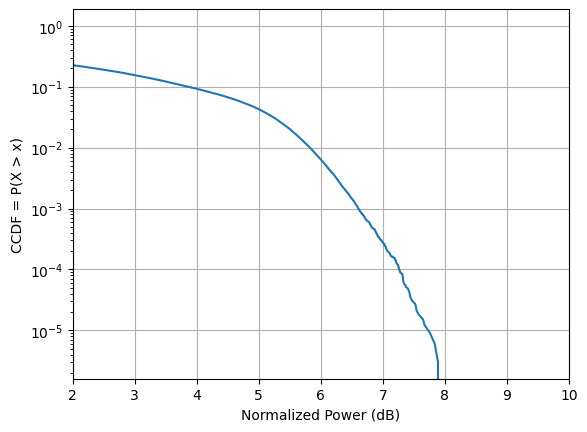

In [11]:
# Plot
plt.figure()
plt.plot(x_sorted, ccdf)
# plt.plot(x_sorted2, ccdf2)
# plt.plot(x_sorted3, ccdf3)
# plt.plot(x_sorted4, ccdf4)
plt.xlabel("Normalized Power (dB)")
plt.xlim(2,10)
plt.ylabel("CCDF = P(X > x)")
plt.yscale("log")   # optional, very common
plt.grid(True)
plt.show()

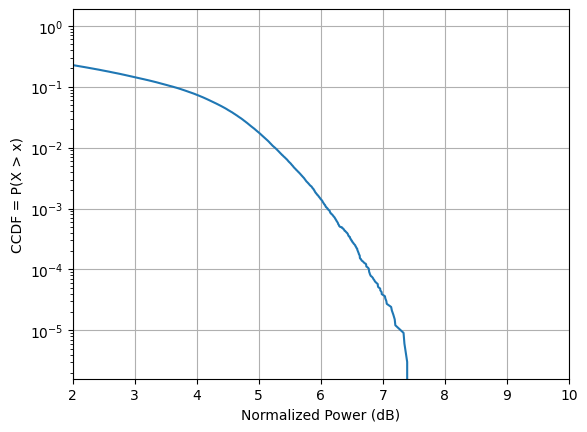